Text loaded successfully!

Artificial intelligence is transforming the world.
Machine learning is a branch of artificial intelligence.
Deep learning uses neural networks to learn patterns.
Natural language processing helps computers understand text.


Tokenized Sentences:
[['artificial', 'intelligence', 'is', 'transforming', 'the', 'world'], ['machine', 'learning', 'is', 'a', 'branch', 'of', 'artificial', 'intelligence'], ['deep', 'learning', 'uses', 'neural', 'networks', 'to', 'learn', 'patterns'], ['natural', 'language', 'processing', 'helps', 'computers', 'understand', 'text']]

CBOW Model Training Completed!

Word: learning
Word Embedding:
[-5.9915305e-04  3.4032966e-04  5.2055269e-03  9.0764519e-03
 -9.2781847e-03 -7.2835954e-03  6.4658890e-03  9.2410678e-03
 -5.1548057e-03 -3.9410130e-03  7.3242574e-03 -1.7843640e-03
 -4.6131588e-03  6.6534071e-03 -4.8308582e-03 -1.7904944e-03
  3.0553446e-03  1.0841165e-03 -8.2161296e-03 -9.7790929e-03
  7.4150125e-03  5.1232199e-03  6.7805215e-

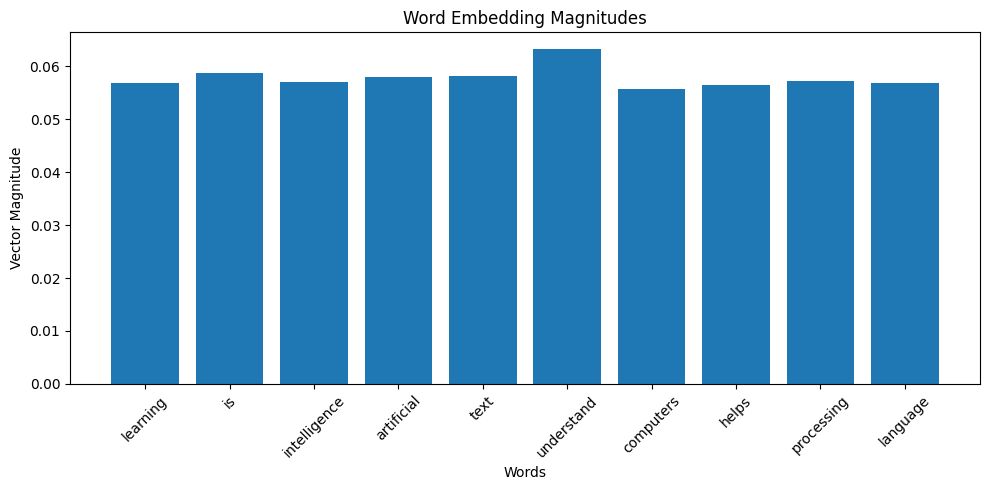


CBOW Model Saved Successfully!


In [2]:

# STEP 1: Import Libraries

import re
import numpy as np
import matplotlib.pyplot as plt
from gensim.models import Word2Vec


# STEP 2: Load Text File

file_path = r"F:\lp4\LP IV Updated Datasets\test.txt " # Change this path

with open(file_path, "r", encoding="utf-8") as file:
    text = file.read()

print("Text loaded successfully!")
print(text[:500])


# STEP 3: Data Preprocessing

text = text.lower()

# Remove special characters and numbers
text = re.sub(r'[^a-z\s.]', '', text)

# Split text into sentences
sentences = text.split('.')

# Tokenize sentences
tokenized_sentences = []

for sentence in sentences:
    words = sentence.split()

    if len(words) > 1:
        tokenized_sentences.append(words)

print("\nTokenized Sentences:")
print(tokenized_sentences[:10])


# STEP 4: Train Word2Vec CBOW Model

model = Word2Vec(
    sentences=tokenized_sentences,
    vector_size=100,
    window=2,
    min_count=1,
    workers=4,
    sg=0,
    epochs=100
)

print("\nCBOW Model Training Completed!")


# STEP 5: Display Word Embeddings

word = list(model.wv.index_to_key)[0]

print("\nWord:", word)
print("Word Embedding:")
print(model.wv[word])


# STEP 6: Find Similar Words

print("\nSimilar Words:")

similar_words = model.wv.most_similar(word, topn=5)

for w, score in similar_words:
    print(w, score)


# STEP 7: Calculate Similarity Between Two Words

words = model.wv.index_to_key

if len(words) >= 2:
    word1 = words[0]
    word2 = words[1]

    similarity = model.wv.similarity(word1, word2)

    print("\nSimilarity between", word1, "and", word2)
    print(similarity)


# STEP 8: Visualize Word Embeddings

words = model.wv.index_to_key[:10]

vectors = np.array([model.wv[w] for w in words])

plt.figure(figsize=(10, 5))

plt.bar(words, np.linalg.norm(vectors, axis=1))

plt.title("Word Embedding Magnitudes")
plt.xlabel("Words")
plt.ylabel("Vector Magnitude")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# STEP 9: Save the Trained Model

model.save("cbow_model.model")

print("\nCBOW Model Saved Successfully!")
